# scArches sensitivity check

Run `4_cell_line_gsea_mlm_concordance.ipynb` first for the primary
MLM scores. The scArches query model is an alternative representation
of the same cells. This notebook repeats the matching and MLM concordance
check using `k=50`, tumor-only Leiden resolution 0.9, and Leiden seed 0
(the seed passing the `< 50` cell fragment and `<= 15%` max-share screens
on the scArches graph).

The joint representation remains the primary analysis.

In [1]:
from pathlib import Path
import sys

import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bio import matching, mlm, plots
from src.utils import load_config

cfg = load_config()
paths = cfg["paths"]
bio = cfg.get("bio", {})
FIG_DIR = ROOT / paths["bio"]["figures"] / "scarches"
FIG_DIR.mkdir(parents=True, exist_ok=True)

K_MATCHING = int(bio.get("matching", {}).get("k", 50))
MARGIN = float(bio.get("matching", {}).get("margin", 0.10))
TUMOR_RES = 0.9
LEIDEN_SEED = 0
GRAPH_SEED = 0
FORCE_RECOMPUTE = False

## Model and matching artifact

The scArches winner is read from the frozen ranking table. The compact
cached artifact stores the latent representation, UMAP, tumor labels, and
matching groups, so reruns avoid reloading the 10,000-gene model.

In [2]:
best = pd.read_csv(ROOT / "models" / "hpo" / "best_models_primary_100.csv")
winner = best.loc[best["approach"].eq("scarches")].iloc[0]
config_id = int(winner["config_id"])
num_hvg = int(winner["num_hvg"])
run_dir = ROOT / paths["hpo"]["runs"] / f"hvg{num_hvg}" / f"config_{config_id:02d}" / "scarches"
model_dir = run_dir / "query"
hvg_file = run_dir.parents[1] / "hvg_genes.txt"
de_dir = ROOT / paths["bio"]["de_scarches"]
de_dir.mkdir(parents=True, exist_ok=True)
matching_artifact = de_dir / "scarches_latent_groups.h5ad"

combined, built = matching.load_or_build_scarches_artifact(
    matching_artifact,
    ROOT / paths["bio"]["joint_artifact"],
    model_dir,
    hvg_file,
    num_hvg,
    TUMOR_RES,
    LEIDEN_SEED,
    graph_seed=GRAPH_SEED,
    force=FORCE_RECOMPUTE,
)
print(f"scArches winner: config {config_id}, {num_hvg} HVGs")
print(f"artifact ({matching_artifact.relative_to(ROOT)}): {'rebuilt' if built else 'loaded from cache'}")

scArches winner: config 47, 10000 HVGs
artifact (models/validation/bio_scarches_cfg47/de_signatures/scarches_latent_groups.h5ad): loaded from cache


In [3]:
size_table, diag = matching.scarches_cluster_diagnostics(
    combined.obs,
    sc_group_col="match_group_scarches",
    joint_col=f"tumor_leiden_res{TUMOR_RES}",
)
print(f"Clusters: {diag['n_clusters']} | min {diag['min_size']} | max {diag['max_size']}")
print(f"Max share: {diag['max_share']:.3f} | fragments (<50): {diag['fragments_lt_50']}")
print(f"ARI vs joint partition: {diag['ari_vs_joint']:.3f} | AMI vs Pelka labels: {diag['ami_vs_pelka']:.3f}")
print(f"cE03-dominated clusters: {diag['cE03_clusters']}")
size_table

Clusters: 17 | min 217 | max 12113
Max share: 0.112 | fragments (<50): 0
ARI vs joint partition: 0.482 | AMI vs Pelka labels: 0.440
cE03-dominated clusters: ['tumor_3', 'tumor_4', 'tumor_11', 'tumor_12', 'tumor_13', 'tumor_16']


,cells,share
match_group_scarches,,
0,12113,0.112
1,9363,0.087
2,8073,0.075
3,11533,0.107
4,7629,0.071
5,1497,0.014
6,3217,0.030
7,6481,0.060
8,10616,0.098


## Candidate matching

The same shared matching function is used as in the joint notebook.
Leiden cluster IDs are arbitrary across independent runs, so candidate
identities are also compared after mapping each scArches cluster to the
joint cluster with the largest cell overlap.

In [4]:
is_tumor = combined.obs["dataset"].eq("tumor").to_numpy()
sc_groups = combined.obs["match_group_scarches"].astype(str)
composition, line_matches, baseline, tumor_order = matching.match_lines(
    combined.obsm["X_latent_scarches"],
    sc_groups,
    combined.obs,
    K_MATCHING,
    margin=MARGIN,
)
line_order = matching.line_order(line_matches)
line_matches = line_matches.loc[line_order]

joint_groups = matching.make_match_groups(combined.obs, f"tumor_leiden_res{TUMOR_RES}")
_, joint_matches, joint_baseline, _ = matching.match_lines(
    combined.obsm["X_latent"], joint_groups, combined.obs, K_MATCHING, margin=MARGIN
)
joint_matches = joint_matches.loc[line_order]

map_to_joint, _ = matching.map_clusters_by_overlap(
    sc_groups, combined.obs[f"tumor_leiden_res{TUMOR_RES}"], is_tumor
)

comparison = pd.DataFrame(
    {
        "joint_primary": joint_matches["primary_match"],
        "joint_margin": joint_matches["margin"],
        "scarches_primary": line_matches["primary_match"],
        "scarches_margin": line_matches["margin"],
    }
)
comparison["scarches_primary_mapped"] = comparison["scarches_primary"].map(
    lambda group: "tumor_" + map_to_joint.get(str(group).replace("tumor_", ""), "")
)
comparison["same_primary"] = comparison["joint_primary"].eq(comparison["scarches_primary"])
comparison["same_primary_mapped"] = comparison["joint_primary"].eq(
    comparison["scarches_primary_mapped"]
)
print(f"scArches tumor-tumor q95 baseline: {baseline:.3f} (joint: {joint_baseline:.3f})")
print(f"same primary label: {int(comparison['same_primary'].sum())} / {len(comparison)}")
print(f"same primary after cluster mapping: {int(comparison['same_primary_mapped'].sum())} / {len(comparison)}")
comparison.round(3)

scArches tumor-tumor q95 baseline: 1.370 (joint: 1.631)
same primary label: 0 / 10
same primary after cluster mapping: 4 / 10


,joint_primary,joint_margin,scarches_primary,scarches_margin,scarches_primary_mapped,same_primary,same_primary_mapped
cell_line,,,,,,,
LS1034,tumor_4,0.073,tumor_1,0.173,tumor_3,False,False
SNUC4,tumor_5,0.019,tumor_3,0.440,tumor_4,False,False
LS180,tumor_4,0.143,tumor_3,0.388,tumor_4,False,True
CL34,tumor_4,0.027,tumor_3,0.328,tumor_4,False,True
CCK81,tumor_5,0.264,tumor_3,0.186,tumor_4,False,False
HT55,tumor_4,0.216,tumor_3,0.062,tumor_4,False,True
HCC56,tumor_4,0.279,tumor_3,0.022,tumor_4,False,True
NCIH747,tumor_5,0.132,tumor_4,0.520,tumor_12,False,False
OUMS23,tumor_6,0.281,tumor_4,0.240,tumor_12,False,False


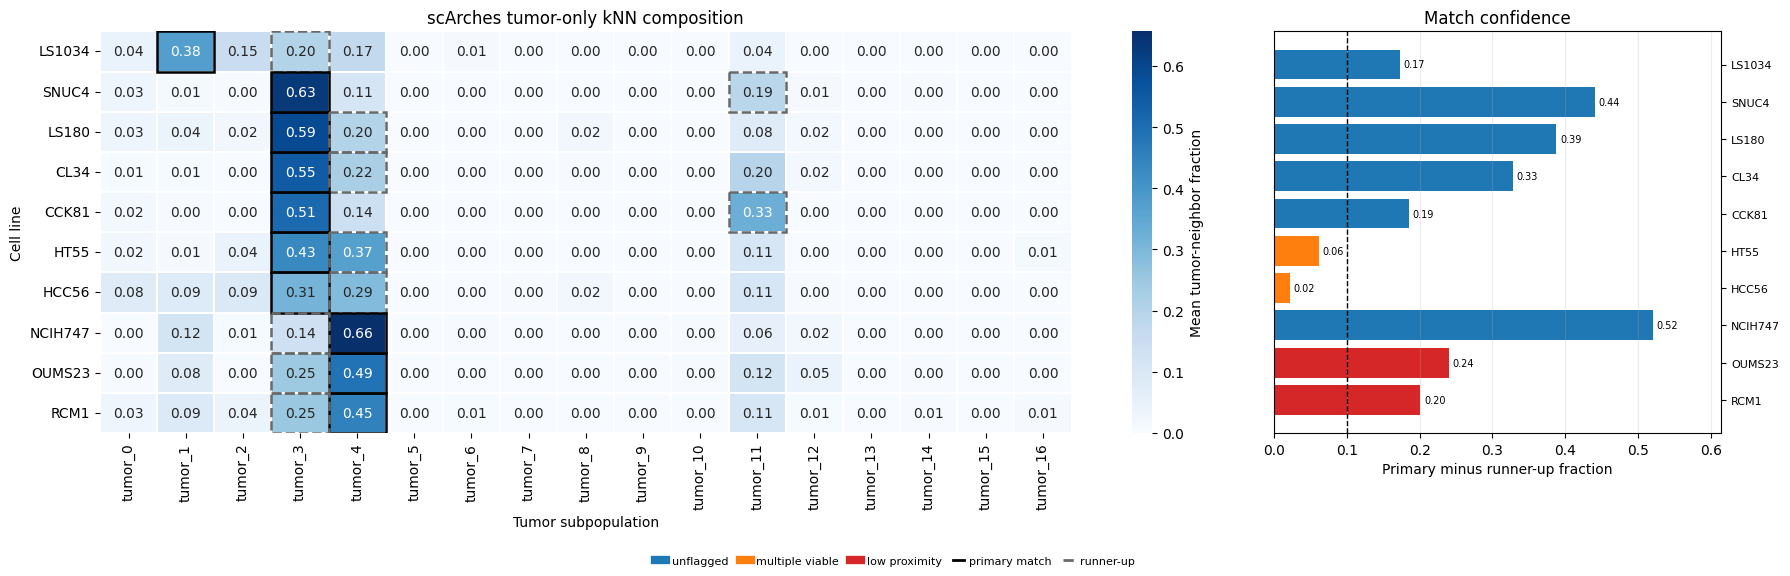

In [5]:
line_composition = (
    composition.groupby("cell_line", observed=True)[tumor_order]
    .mean()
    .loc[line_order]
)
plots.plot_composition_and_margin(
    line_composition,
    line_matches,
    tumor_order,
    line_order,
    FIG_DIR / "scarches_matching_confidence.png",
    title="scArches tumor-only kNN composition",
)
plt.show()

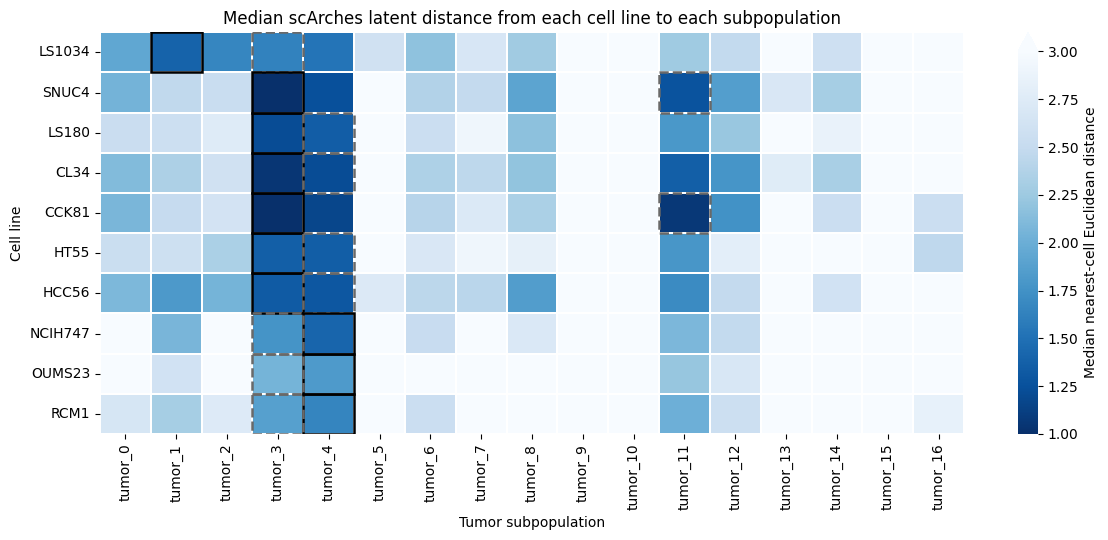

In [6]:
line_distance = matching.subpopulation_distances(
    combined.obsm["X_latent_scarches"],
    sc_groups,
    combined.obs,
    tumor_order=tumor_order,
    row_order=line_order,
)
plots.plot_distance_heatmap(
    line_distance,
    line_matches,
    FIG_DIR / "scarches_line_subpop_distances.png",
    title="Median scArches latent distance from each cell line to each subpopulation",
)
plt.show()

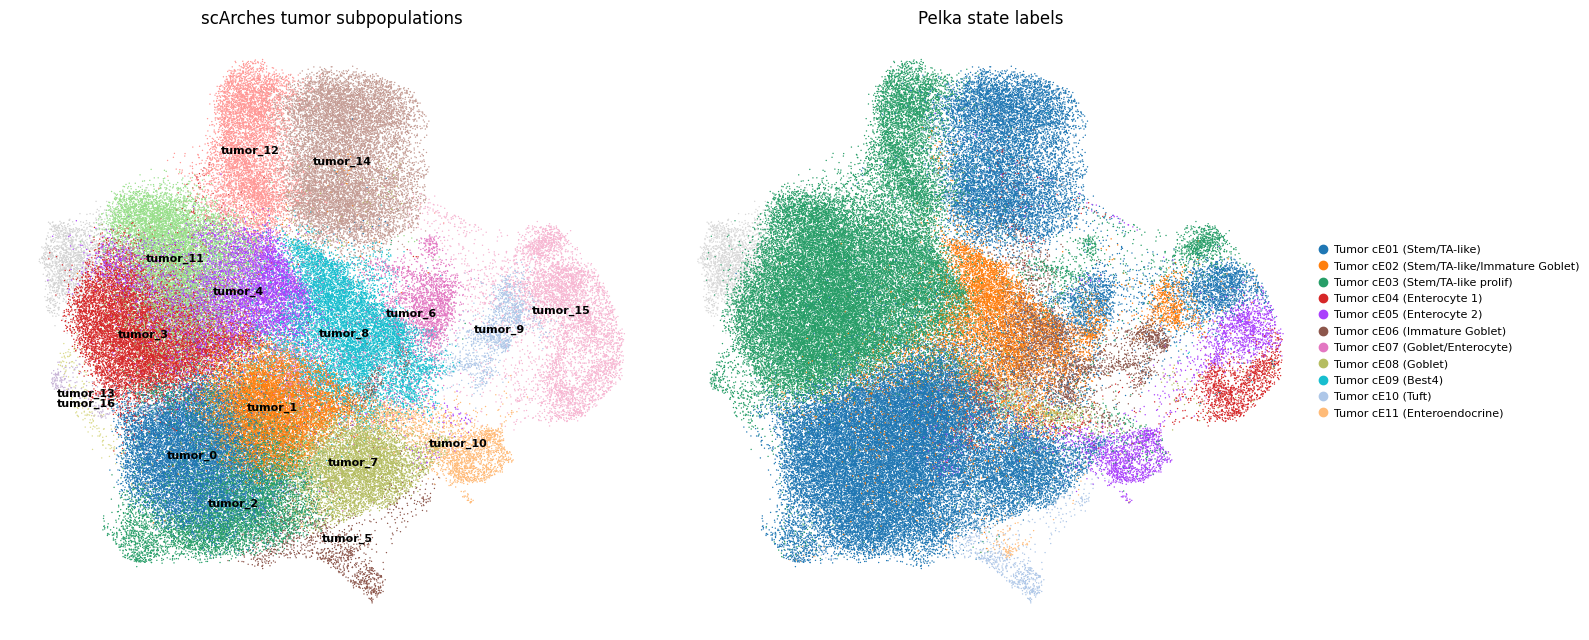

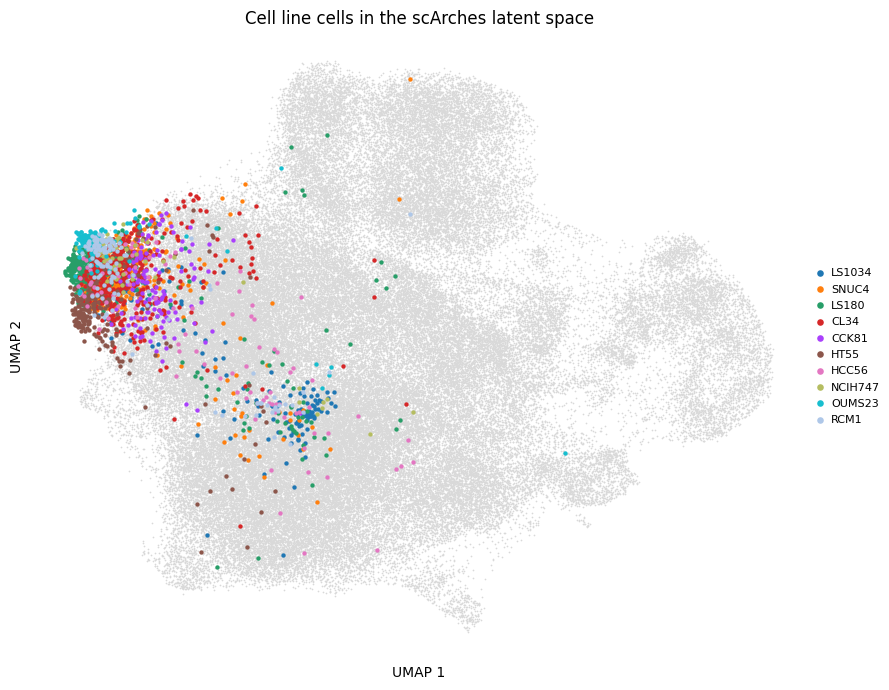

In [7]:
plots.plot_subpopulation_umap(
    combined,
    "match_group_scarches",
    "label",
    FIG_DIR / "scarches_subpop_umap.png",
    basis="X_umap_scarches",
    subpop_title="scArches tumor subpopulations",
    group_order=tumor_order,
)
plt.show()

plots.plot_line_umap(
    combined,
    line_order,
    FIG_DIR / "scarches_line_umap.png",
    basis="X_umap_scarches",
    title="Cell line cells in the scArches latent space",
)
plt.show()

## MLM concordance in the scArches groups

The joint per-cell MLM scores are model-independent and reused here;
only the group labels change. The numeric runner-up table is shown
below.

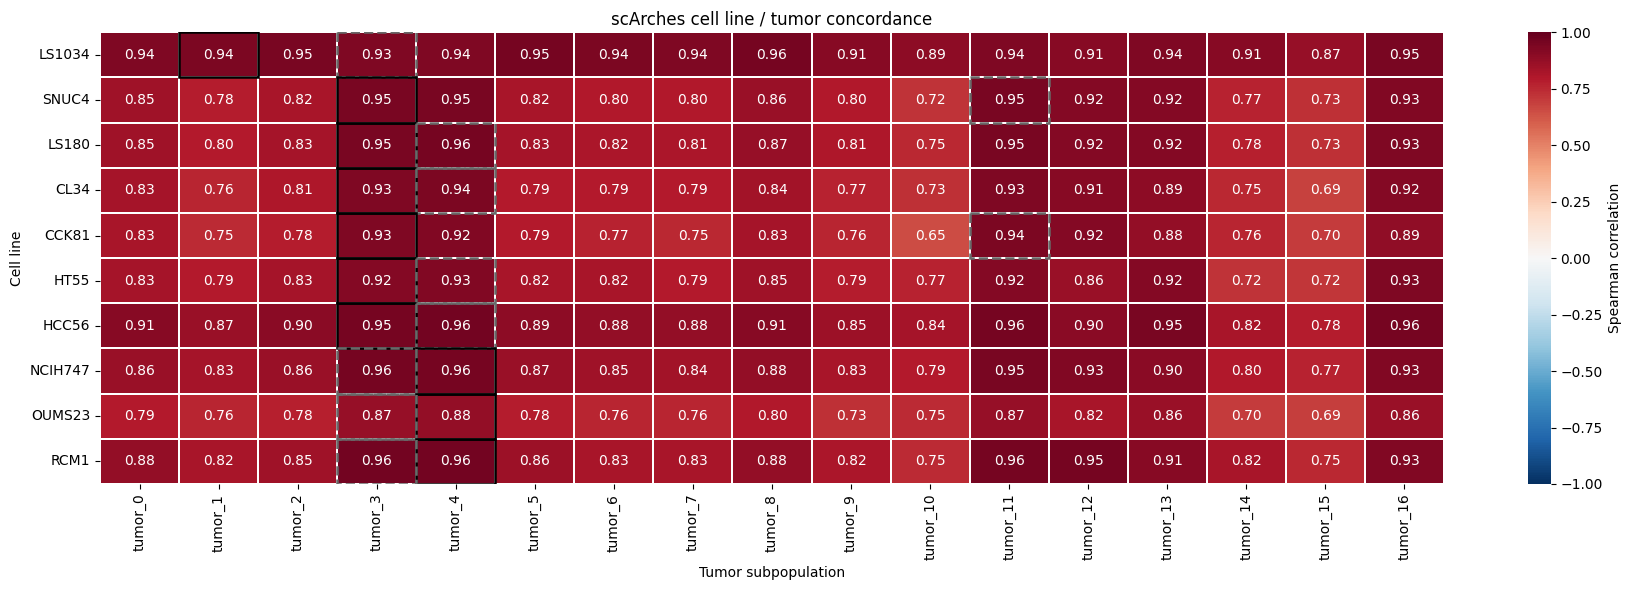

In [8]:
joint_de_dir = ROOT / paths["bio"]["de_joint"]
mlm_path = joint_de_dir / "hallmark_mlm" / "hallmark_mlm_scores.h5ad"
assert mlm_path.exists(), f"Run 4_cell_line_gsea_mlm_concordance.ipynb first: {mlm_path}"
pathway_scores, score_obs, _ = mlm.load_scores(mlm_path)
score_obs["group"] = combined.obs.loc[score_obs.index, "match_group_scarches"].astype(str)

sc_line_order = [str(line).replace("line_", "") for line in line_order]
concordance_mat = mlm.concordance_matrix(
    pathway_scores, score_obs, sc_line_order, tumor_order
)
plots.plot_concordance(
    concordance_mat,
    line_matches,
    FIG_DIR / "scarches_mlm_concordance.png",
    title="scArches cell line / tumor concordance",
)
plt.show()

In [9]:
runner_up = mlm.primary_runner_up(concordance_mat, line_matches)
display(runner_up.round(3))


,cell_line,primary_match,runner_up,primary_rho,runner_up_rho,primary_minus_runner_up
0,CL34,tumor_3,tumor_4,0.931,0.944,-0.013
1,HCC56,tumor_3,tumor_4,0.955,0.963,-0.008
2,CCK81,tumor_3,tumor_11,0.932,0.938,-0.006
3,HT55,tumor_3,tumor_4,0.920,0.926,-0.005
4,LS180,tumor_3,tumor_4,0.951,0.956,-0.005
5,RCM1,tumor_4,tumor_3,0.962,0.965,-0.003
6,SNUC4,tumor_3,tumor_11,0.949,0.949,-0.000
7,NCIH747,tumor_4,tumor_3,0.961,0.956,0.004
8,OUMS23,tumor_4,tumor_3,0.881,0.872,0.009
9,LS1034,tumor_1,tumor_3,0.943,0.931,0.011


## Summary

The summary compares the latent candidate with the MLM concordance
readout.

In [10]:
summary = line_matches[
    [
        "n_cells",
        "primary_match",
        "primary_frac",
        "second_match",
        "margin",
        "median_dist_nearest_tumor",
        "low_proximity",
    ]
].copy()
summary["joint_primary"] = joint_matches["primary_match"]
summary["joint_primary_mapped"] = summary["primary_match"].map(
    lambda group: "tumor_" + map_to_joint.get(str(group).replace("tumor_", ""), "")
)
summary["same_primary_as_joint"] = summary["primary_match"].eq(summary["joint_primary"])
summary["same_primary_as_joint_mapped"] = summary["joint_primary"].eq(
    summary["joint_primary_mapped"]
)
summary["mlm_primary_rho"] = [
    float(concordance_mat.loc[str(line).replace("line_", ""), summary.loc[line, "primary_match"]])
    for line in summary.index
]
summary["mlm_runner_up_rho"] = [
    float(concordance_mat.loc[str(line).replace("line_", ""), summary.loc[line, "second_match"]])
    for line in summary.index
]
summary["mlm_primary_minus_runner_up"] = (
    summary["mlm_primary_rho"] - summary["mlm_runner_up_rho"]
)
summary.to_csv(de_dir / "scarches_summary.csv")
summary.round(3)

,n_cells,primary_match,primary_frac,second_match,margin,median_dist_nearest_tumor,low_proximity,joint_primary,joint_primary_mapped,same_primary_as_joint,same_primary_as_joint_mapped,mlm_primary_rho,mlm_runner_up_rho,mlm_primary_minus_runner_up
cell_line,,,,,,,,,,,,,,
LS1034,153,tumor_1,0.376,tumor_3,0.173,1.153,False,tumor_4,tumor_3,False,False,0.943,0.931,0.011
SNUC4,471,tumor_3,0.631,tumor_11,0.440,0.934,False,tumor_5,tumor_4,False,False,0.949,0.949,-0.000
LS180,362,tumor_3,0.590,tumor_4,0.388,1.118,False,tumor_4,tumor_4,False,True,0.951,0.956,-0.005
CL34,418,tumor_3,0.548,tumor_4,0.328,0.970,False,tumor_4,tumor_4,False,True,0.931,0.944,-0.013
CCK81,127,tumor_3,0.512,tumor_11,0.186,0.876,False,tumor_5,tumor_4,False,False,0.932,0.938,-0.006
HT55,211,tumor_3,0.433,tumor_4,0.062,1.208,False,tumor_4,tumor_4,False,True,0.920,0.926,-0.005
HCC56,102,tumor_3,0.313,tumor_4,0.022,1.091,False,tumor_4,tumor_4,False,True,0.955,0.963,-0.008
NCIH747,80,tumor_4,0.656,tumor_3,0.520,1.346,False,tumor_5,tumor_12,False,False,0.961,0.956,0.004
OUMS23,107,tumor_4,0.487,tumor_3,0.240,1.702,True,tumor_6,tumor_12,False,False,0.881,0.872,0.009
